# Tema 2 · Python II: funciones y colecciones

Organizar el código en funciones y guardar datos en listas y diccionarios.

Este cuaderno es el tema 2 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/ruta/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/ruta/2-python-ii-funciones-y-colecciones/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

# Teoría

## La pregunta

Tienes un texto largo: una noticia, un cuento, los mensajes de un grupo. ¿Cuál es la palabra que más se repite? Leerlo y contar a mano funciona con un párrafo, pero no con mil páginas.

Con lo del tema 1 (variables, decisiones y bucles) casi podrías hacerlo, pero te faltan dos cosas: una manera de **guardar muchos datos juntos** (todas las palabras, y cuántas veces aparece cada una) y una manera de **ordenar el código** en piezas con nombre que puedas usar una y otra vez. Eso son las **colecciones** y las **funciones**, y con ellas está escrito todo el código de inteligencia artificial que vas a ver en esta ruta. Contar palabras, además, es exactamente el primer paso con el que una computadora empieza a «leer» un texto.

En este tema vas a:

- escribir **funciones** con parámetros y `return`;
- guardar datos en **listas**, **tuplas**, **diccionarios** y **conjuntos**, y transformar listas con **comprensiones**;
- **contar frecuencias** con un diccionario y ordenarlas con `sorted`;
- leer y escribir **archivos CSV** con `open` y con el módulo `csv`;
- usar **módulos** con `import` e instalar paquetes con `pip`;
- entender qué es una **clase**, lo justo para reconocer `modelo.fit()` cuando aparezca.

Necesitas lo del tema 1: variables, `if`, bucles `for` y `while`, y f-strings.

## Actividad: el diccionario vivo

Antes de escribir código, mira cómo cuenta una computadora. Escribe una frase (o deja la que está) y pulsa «Siguiente palabra». El programa lee las palabras una por una y va llenando una tabla: a la izquierda, cada palabra distinta (la **clave**); a la derecha, cuántas veces apareció (la **cuenta**). Si la palabra es nueva, se agrega una fila con 1; si ya estaba, su cuenta sube en 1.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/ruta/2-python-ii-funciones-y-colecciones/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Con «Limpiar el texto» apagado, llena la tabla. ¿Cuántas veces cuenta la palabra *pan*? ¿Por qué aparecen «pan,» y «¡Pan!» en filas separadas?
2. Enciende «Limpiar el texto» y vuelve a llenar. ¿Qué cambió en la cantidad de filas y en la cuenta de *pan*?
3. Enciende «Ordenar por cuenta». Las palabras que más se repiten, ¿son las más interesantes del texto?
4. Escribe una frase tuya donde una palabra aparezca con mayúscula y con punto, y predice cuántas filas va a tener la tabla antes de llenarla.

Lo que acabas de ver son dos ideas de este tema: **un diccionario es una tabla de búsqueda** (dada una palabra, encuentra su cuenta al instante) y **los datos crudos casi siempre necesitan limpieza** antes de contarlos. Para la computadora, «Pan», «pan,» y «pan» son tres textos distintos hasta que tú le digas lo contrario.

## Funciones: código con nombre

Una **función** es un pedazo de código con nombre que recibe datos, hace algo con ellos y devuelve un resultado. Ya usaste varias: `print`, `len`, `int`. Ahora vas a escribir las tuyas con `def`:

In [ ]:
def celsius_a_fahrenheit(celsius):
    """Convierte una temperatura de grados Celsius a Fahrenheit."""
    return celsius * 9 / 5 + 32

print(celsius_a_fahrenheit(0))
print(celsius_a_fahrenheit(25))
temperatura = celsius_a_fahrenheit(-10)
print(f"-10 °C son {temperatura} °F")

32.0
77.0
-10 °C son 14.0 °F


- `def` empieza la función, `celsius_a_fahrenheit` es su nombre y `celsius` es su **parámetro**: una variable que recibe el valor que le pases al **llamarla**.
- El texto entre triples comillas es la **documentación**: dice qué hace la función. No es obligatorio, pero te ayuda a ti y a quien lea tu código.
- `return` termina la función y **devuelve** un valor, que puedes imprimir o guardar en una variable.

Una función puede tener varios parámetros, y alguno puede tener un **valor por defecto** que se usa cuando no lo pasas:

In [ ]:
def nota_final(parcial, examen, peso_examen=0.6):
    """Promedio ponderado: el examen pesa peso_examen."""
    return parcial * (1 - peso_examen) + examen * peso_examen

print(nota_final(70, 80))                    # el examen pesa 0.6
print(nota_final(70, 80, peso_examen=0.5))   # ahora pesa la mitad

76.0
75.0


**`print` no es lo mismo que `return`.** `print` muestra un valor en la pantalla y nada más; `return` lo entrega a quien llamó la función para que lo siga usando. Una función sin `return` devuelve un valor especial, `None` («nada»):

In [ ]:
def doble_que_imprime(x):
    print(2 * x)

def doble_que_devuelve(x):
    return 2 * x

a = doble_que_imprime(5)
b = doble_que_devuelve(5)
print(a, b)

10
None 10


El `10` de la primera línea lo escribió `print` dentro de la función, pero `a` quedó vacía. Si quieres usar el resultado después, usa `return`.

### El ámbito: lo que pasa en la función se queda en la función

Las variables que creas dentro de una función son **locales**: existen mientras la función corre y desaparecen al terminar. Afuera no se ven:

*La celda que sigue da un error a propósito: es parte de la explicación.*

In [ ]:
def duplicar(x):
    resultado = 2 * x
    return resultado

print(duplicar(21))
print(resultado)

42
Traceback (most recent call last):
  ...
NameError: name 'resultado' is not defined


Esto es una ventaja: puedes usar los nombres que quieras dentro de una función sin pisar las variables del resto del programa. Lo que quieras sacar de una función, sácalo con `return`.

## Listas: muchos valores juntos

Una **lista** guarda varios valores en orden, entre corchetes y separados por comas. Cada valor tiene una **posición** (su índice), que empieza en 0:

In [ ]:
notas = [72, 85, 58, 91, 64]

print(notas[0])      # la primera
print(notas[-1])     # la última: los índices negativos cuentan desde atrás
print(notas[1:3])    # una rebanada: de la posición 1 hasta antes de la 3
print(len(notas), sum(notas), min(notas), max(notas))

notas.append(77)     # agrega un valor al final
notas[2] = 60        # cambia el valor de la posición 2
print(notas)
print(91 in notas)   # ¿está el 91 en la lista?

72
64
[85, 58]
5 370 58 91
[72, 85, 60, 91, 64, 77]
True


`len`, `sum`, `min` y `max` reciben una lista entera y te ahorran un bucle. `append` es un **método**: una función que pertenece a la lista y se llama con un punto, `notas.append(77)`.

### Recorrer y transformar una lista

Un `for` recorre una lista valor por valor. Para crear una lista nueva a partir de otra, empiezas con una lista vacía y le vas agregando:

In [ ]:
# Sumar 5 puntos de bono a cada nota
con_bono = []
for n in notas:
    con_bono.append(n + 5)
print(con_bono)

[77, 90, 65, 96, 69, 82]


Esto es tan común que Python tiene una forma corta, la **comprensión de lista**: «la lista de `n + 5` para cada `n` en `notas`». Se le puede agregar un `if` al final para quedarse solo con algunos valores:

In [ ]:
con_bono = [n + 5 for n in notas]
altas = [n for n in notas if n >= 80]
print(con_bono)
print(altas)
print(f"{len(altas)} de {len(notas)} notas son de 80 o más")

[77, 90, 65, 96, 69, 82]
[85, 91]
2 de 6 notas son de 80 o más


Lee la comprensión de izquierda a derecha como una frase: *qué* guardas (`n + 5`), *de dónde* lo sacas (`for n in notas`) y, si quieres, *con qué condición* (`if n >= 80`).

Las funciones y las listas se llevan bien. Esta función recibe una lista y devuelve un número. Para mostrarlo usamos `round(x, 1)`, otra función que ya viene con Python: redondea `x` a 1 decimal:

In [ ]:
def promedio(valores):
    """El promedio de una lista de números."""
    return sum(valores) / len(valores)

print(round(promedio(notas), 1))
print(promedio([10, 20]))

74.8
15.0


## Tuplas, diccionarios y conjuntos

### Tuplas: valores que van juntos

Una **tupla** es como una lista, pero entre paréntesis y **no se puede cambiar** una vez creada. Sirve para valores que van siempre juntos, como el nombre y la edad de una persona. Se puede **desempaquetar** en varias variables a la vez:

*La celda que sigue da un error a propósito: es parte de la explicación.*

In [ ]:
persona = ("Ana", 15)
nombre, edad = persona          # desempaquetar
print(nombre, "tiene", edad, "años")
persona[1] = 16

Ana tiene 15 años
Traceback (most recent call last):
  ...
TypeError: 'tuple' object does not support item assignment


### Diccionarios: una tabla de búsqueda

Un **diccionario** guarda pares **clave → valor**, entre llaves. En lugar de buscar por posición, buscas por clave, igual que en un diccionario de verdad buscas una palabra para encontrar su significado:

In [ ]:
edades = {"Ana": 15, "Luis": 16, "Sofía": 14}

print(edades["Luis"])        # buscar por clave
edades["Marco"] = 15         # agregar una clave nueva
edades["Ana"] = 16           # cambiar el valor de una clave
print(len(edades), "personas")

for nombre, edad in edades.items():
    print(f"{nombre}: {edad} años")

16
4 personas
Ana: 16 años
Luis: 16 años
Sofía: 14 años
Marco: 15 años


- `edades.items()` da los pares (clave, valor) como tuplas, y el `for` los desempaqueta.
- Las claves no se repiten: si asignas una clave que ya existe, cambias su valor.
- El diccionario recuerda el orden en que agregaste las claves.

Si buscas una clave que no existe, Python se queja con un `KeyError`. El método `get` busca sin quejarse y devuelve un valor por defecto:

*La celda que sigue da un error a propósito: es parte de la explicación.*

In [ ]:
print("Pedro" in edades)
print(edades.get("Pedro", 0))
print(edades["Pedro"])

False
0
Traceback (most recent call last):
  ...
KeyError: 'Pedro'


### Conjuntos: sin repetidos

Un **conjunto** (`set`) guarda valores **sin repetir y sin orden**. Es la forma más rápida de saber qué valores distintos hay o de preguntar si algo está:

In [ ]:
colores = ["rojo", "azul", "rojo", "verde", "azul", "rojo"]
distintos = set(colores)
print(len(colores), "colores anotados,", len(distintos), "distintos")
print(sorted(distintos))
print("amarillo" in distintos)

6 colores anotados, 3 distintos
['azul', 'rojo', 'verde']
False


Como un conjunto no tiene orden, para mostrarlo conviene pasarlo por `sorted`, que devuelve una lista ordenada.

| Colección | Se escribe | ¿Ordenada? | ¿Se puede cambiar? | Para qué sirve |
|---|---|---|---|---|
| Lista | `[1, 2, 2]` | Sí, por posición | Sí | Una secuencia de valores |
| Tupla | `("Ana", 15)` | Sí, por posición | No | Valores que van juntos |
| Diccionario | `{"Ana": 15}` | Por orden de llegada | Sí | Buscar un valor por su clave |
| Conjunto | `{1, 2}` | No | Sí | Valores distintos, sin repetir |

## Contar las palabras de un texto

Ya tienes todo para responder la pregunta del principio. Este es un texto de ejemplo, escrito para este tema. Las triples comillas permiten escribir un texto de varias líneas:

In [ ]:
texto = """La panadería del barrio abre temprano. A las seis ya huele a pan,
y a las siete la fila llega a la esquina. El pan de la mañana se acaba
rápido: la gente compra pan para el desayuno y pan para el colegio. Por la
tarde la panadería hace galletas, y los niños del barrio pasan a comprar
galletas al salir del colegio."""

**Primero, limpiar.** Como viste en la actividad, «Pan», «pan,» y «pan» tienen que contar como la misma palabra. Esta función pasa todo a minúsculas y cambia cada signo de puntuación por un espacio. `c.isalnum()` dice si el carácter `c` es una letra o un número, y `c.isspace()`, si es un espacio o un salto de línea. `limpio += c` es una forma corta de escribir `limpio = limpio + c` (con números, `n += 1` suma 1 a `n`):

In [ ]:
def limpiar(texto):
    """Pasa a minúsculas y cambia la puntuación por espacios."""
    limpio = ""
    for c in texto.lower():
        if c.isalnum() or c.isspace():
            limpio += c
        else:
            limpio += " "
    return limpio

palabras = limpiar(texto).split()   # split corta en los espacios
print(palabras[:8])
print(len(palabras), "palabras")

['la', 'panadería', 'del', 'barrio', 'abre', 'temprano', 'a', 'las']
63 palabras


**Después, contar.** Un diccionario palabra → cuenta, exactamente como en la actividad: si la palabra ya está, su cuenta sube en 1; si no, entra con 1.

In [ ]:
def contar(palabras):
    """Diccionario con cuántas veces aparece cada palabra."""
    conteo = {}
    for palabra in palabras:
        if palabra in conteo:
            conteo[palabra] += 1
        else:
            conteo[palabra] = 1
    return conteo

conteo = contar(palabras)
print(len(conteo), "palabras distintas")
print("pan:", conteo["pan"], "  la:", conteo["la"])

38 palabras distintas
pan: 4   la: 7


Las cuatro líneas del `if` se pueden escribir en una con `get`: `conteo[palabra] = conteo.get(palabra, 0) + 1`. Las dos formas hacen lo mismo.

### Ordenar con `sorted` y `key`

Para saber cuáles son las más frecuentes hay que ordenar los pares (palabra, cuenta) **por la cuenta**. `sorted` recibe cualquier colección y devuelve una lista ordenada. Con `key` le dices **según qué** ordenar: una función que, para cada elemento, devuelve el valor que hay que comparar. Con `reverse=True`, de mayor a menor:

In [ ]:
def la_cuenta(par):
    """De un par (palabra, cuenta), devuelve la cuenta."""
    return par[1]

ordenadas = sorted(conteo.items(), key=la_cuenta, reverse=True)
print(ordenadas[:5])

[('la', 7), ('a', 5), ('pan', 4), ('del', 3), ('y', 3)]


Fíjate que se pasa `la_cuenta` sin paréntesis: no la llamas tú, se la entregas a `sorted` para que la llame con cada par. Para funciones tan cortas, Python permite escribirlas en el mismo lugar con `lambda`: `key=lambda par: par[1]` hace lo mismo que `key=la_cuenta`.

### Tu primer gráfico

Una lista de números se entiende mejor dibujada. `matplotlib` es la librería de gráficos que vas a usar en toda la ruta; en el tema 4 la verás a fondo, así que por ahora tómalo como un adelanto. Como vas a dibujar dos veces, conviene una función:

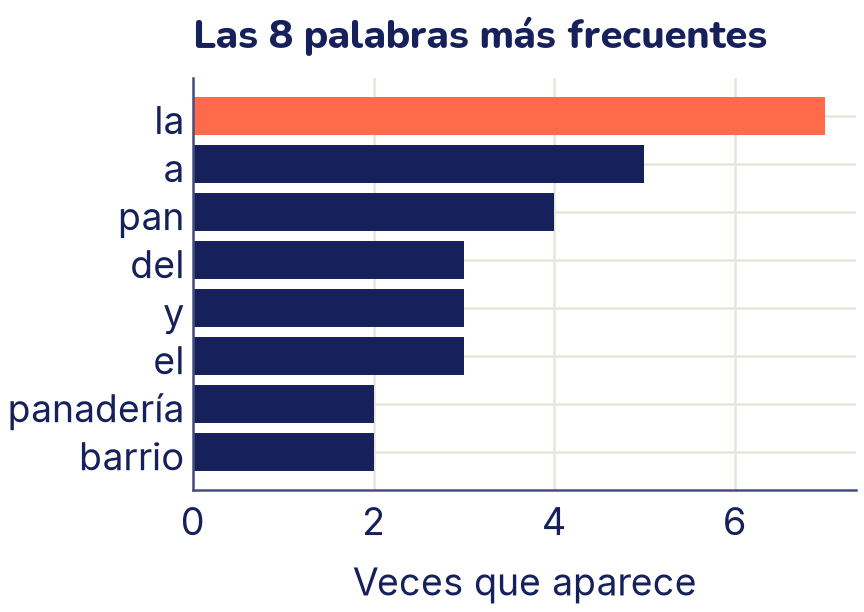

In [ ]:
import matplotlib.pyplot as plt

def graficar_frecuentes(pares, titulo):
    """Barras horizontales con los pares (palabra, cuenta)."""
    palabras_top = [p for p, c in pares]
    cuentas_top = [c for p, c in pares]
    # La primera barra (la más frecuente) en otro color
    colores = ["C1"] + ["C0"] * (len(pares) - 1)
    plt.barh(palabras_top, cuentas_top, color=colores)
    plt.gca().invert_yaxis()       # la más frecuente arriba
    plt.xlabel("Veces que aparece")
    plt.title(titulo)
    plt.show()

graficar_frecuentes(ordenadas[:8], "Las 8 palabras más frecuentes")

Las ganadoras son «la», «a», «del», «y», «el»: palabras que aparecen en cualquier texto en español y no dicen de qué trata este. Se llaman **palabras vacías**. Un conjunto es perfecto para guardarlas, porque solo nos interesa preguntar si una palabra está o no. Y una **comprensión de diccionario**, con la misma idea que la de lista, arma el conteo sin ellas:

[('pan', 4), ('panadería', 2), ('barrio', 2), ('colegio', 2), ('galletas', 2)]


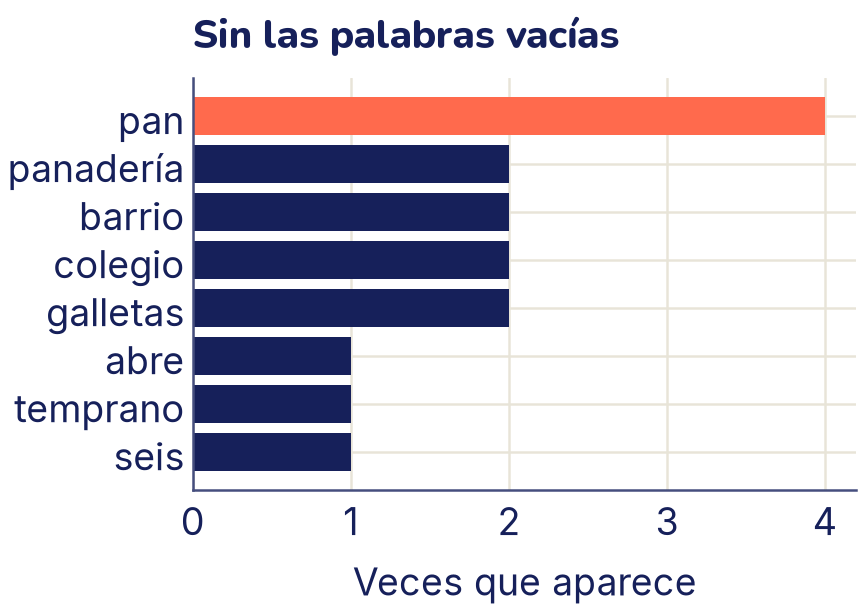

In [ ]:
vacias = {"la", "las", "el", "los", "a", "de", "del", "y", "al",
          "se", "para", "por", "ya"}

conteo_util = {p: c for p, c in conteo.items() if p not in vacias}
ordenadas_util = sorted(conteo_util.items(), key=la_cuenta,
                        reverse=True)
print(ordenadas_util[:5])
graficar_frecuentes(ordenadas_util[:8], "Sin las palabras vacías")

Ahora sí se ve de qué habla el texto: pan, panadería, barrio, galletas, colegio. Con dos funciones cortas, `limpiar` y `contar`, convertiste un texto en números que se pueden comparar y graficar. En el tema 21 vas a ver que así empieza un modelo que clasifica textos: cada texto se convierte en las cuentas de sus palabras.

## Archivos y CSV

Los datos casi nunca están escritos dentro del programa: vienen en archivos. El formato más común para tablas es el **CSV** (*comma-separated values*, valores separados por comas): un archivo de texto con una fila por línea y las columnas separadas por comas. La primera línea suele tener los nombres de las columnas.

### Escribir un archivo

Para trabajar con un archivo, primero se abre con `open`. Con `with`, Python lo cierra solo al terminar el bloque, aunque haya un error. El módulo `csv` sabe escribir filas con las comas en su lugar. Vamos a crear un CSV pequeño con las notas de un curso inventado:

In [ ]:
import csv

filas = [
    ["nombre", "matematica", "lenguaje", "ciencias"],
    ["Ana", 78, 85, 90],
    ["Bruno", 55, 62, 48],
    ["Carla", 92, 88, 95],
    ["Diego", 40, 71, 66],
    ["Elena", 67, 59, 73],
    ["Franco", 85, 77, 81],
]

# "w" abre el archivo para escribir (lo crea o lo reemplaza)
with open("notas.csv", "w", newline="", encoding="utf-8") as f:
    escritor = csv.writer(f)
    escritor.writerows(filas)

Si trabajas en Colab, el archivo aparece en el panel de archivos de la izquierda. `encoding="utf-8"` hace que las tildes y la ñ se guarden bien, y `newline=""` es lo que pide el módulo `csv` para no dejar líneas en blanco de más.

### Leer con `open`, línea por línea

Un archivo abierto para leer se recorre con un `for`, una línea a la vez. Cada línea es un texto que termina en un salto de línea: `strip()` lo quita y `split(",")` corta en las comas:

In [ ]:
with open("notas.csv", encoding="utf-8") as f:
    for linea in f:
        print(linea.strip().split(","))

['nombre', 'matematica', 'lenguaje', 'ciencias']
['Ana', '78', '85', '90']
['Bruno', '55', '62', '48']
['Carla', '92', '88', '95']
['Diego', '40', '71', '66']
['Elena', '67', '59', '73']
['Franco', '85', '77', '81']


Mira las comillas: `'78'` es un **texto**, no un número. Todo lo que se lee de un archivo llega como texto, y hay que convertirlo con `int` o `float` antes de hacer cuentas.

### Leer con el módulo `csv`

Cortar en las comas a mano falla cuando un valor tiene una coma adentro (por ejemplo, «La Paz, Bolivia» entre comillas). `csv.DictReader` lo hace bien y, además, convierte cada fila en un diccionario cuyas claves son los nombres de las columnas. Con eso, el promedio, el mínimo y el máximo de una columna salen sin ninguna librería extra:

In [ ]:
def leer_columna(archivo, columna):
    """Los valores de una columna de un CSV, como números."""
    valores = []
    with open(archivo, encoding="utf-8") as f:
        for fila in csv.DictReader(f):
            valores.append(float(fila[columna]))
    return valores

matematica = leer_columna("notas.csv", "matematica")
print(matematica)
print(f"Promedio: {promedio(matematica):.1f}")
print(f"Mínimo: {min(matematica)}   Máximo: {max(matematica)}")

[78.0, 55.0, 92.0, 40.0, 67.0, 85.0]
Promedio: 69.5
Mínimo: 40.0   Máximo: 92.0


La función `leer_columna` sirve para cualquier columna de cualquier CSV: cambia `"matematica"` por `"lenguaje"` y listo. En el tema 4, la librería `pandas` hará esto en una línea, pero por dentro hace lo mismo que acabas de programar.

## Módulos, `import` y `pip`

Un **módulo** es un archivo de Python con funciones ya escritas que puedes usar. Python trae muchos de fábrica (la «biblioteca estándar»): `csv` es uno, y también `math` para matemáticas, `random` para el azar y `collections`, que tiene un contador ya hecho. Se cargan con `import`:

In [ ]:
import math
import random
from collections import Counter

print(math.sqrt(81), math.pi)

random.seed(1)              # semilla fija: siempre sale lo mismo
print(random.choice(["piedra", "papel", "tijera"]))

# Counter hace en una línea lo que hizo nuestra función contar
print(Counter(palabras).most_common(3))

9.0 3.141592653589793
piedra
[('la', 7), ('a', 5), ('pan', 4)]


- `import math` carga el módulo entero; sus funciones se usan con el nombre del módulo adelante: `math.sqrt`.
- `from collections import Counter` trae solo `Counter`, que se usa sin prefijo.
- `import matplotlib.pyplot as plt` (lo usaste arriba) le pone un apodo corto al módulo.

`Counter` da el mismo resultado que tu función `contar` seguida de `sorted`. Saber programarlo tú te deja entender qué hace por dentro; usar `Counter` te ahorra tiempo. Las dos cosas valen.

### Instalar paquetes con `pip`

Las librerías que no vienen con Python, como `numpy`, `pandas` o `scikit-learn`, se llaman **paquetes** y se instalan con **pip**, el instalador de Python. Si intentas importar un paquete que no está instalado, ves este error:

*La celda que sigue da un error a propósito: es parte de la explicación.*

In [ ]:
import paquete_inventado

Traceback (most recent call last):
  ...
ModuleNotFoundError: No module named 'paquete_inventado'


En Colab ya vienen instalados casi todos los paquetes que usa esta ruta. Cuando falte alguno, se instala escribiendo en una celda el nombre del paquete detrás de `!pip install`. El signo de exclamación le dice a Colab que esa línea no es Python, sino una orden para la computadora:

```text
!pip install wordcloud
```

En tu propia computadora, la misma orden se escribe sin el signo de exclamación en la terminal: `pip install wordcloud`. Instalas una vez; después, en cada programa, basta con el `import`. Ojo: el nombre para instalar y el nombre para importar no siempre coinciden. Por ejemplo, se instala `scikit-learn` y se importa `sklearn`.

## Clases: una pista de lo que viene

Desde el tema 6 vas a escribir líneas como estas:

```text
modelo = LinearRegression()
modelo.fit(X, y)
modelo.predict(X_nuevo)
```

`modelo` es un **objeto**: un valor que guarda sus propios datos y trae sus propias funciones (los **métodos**, como `fit` y `predict`). Una lista también es un objeto, por eso tiene `notas.append(...)`. El molde con que se fabrican objetos de un tipo se llama **clase**. No necesitas escribir muchas clases en esta ruta, pero sí entender cómo funcionan. Esta guarda el conteo de palabras adentro:

In [ ]:
class Contador:
    """Cuenta cuántas veces aparece cada cosa."""

    def __init__(self):
        # Se ejecuta al crear el objeto: empieza con el conteo vacío
        self.conteo = {}

    def agregar(self, cosa):
        self.conteo[cosa] = self.conteo.get(cosa, 0) + 1

    def agregar_todas(self, cosas):
        for cosa in cosas:
            self.agregar(cosa)

    def mas_comunes(self, k):
        pares = sorted(self.conteo.items(), key=lambda par: par[1],
                       reverse=True)
        return pares[:k]

c = Contador()                 # crear un objeto de la clase
c.agregar_todas(palabras)
c.agregar("pan")
print(c.mas_comunes(3))
print(c.conteo["pan"])

[('la', 7), ('a', 5), ('pan', 5)]
5


- `class Contador:` define el molde. `Contador()` fabrica un objeto nuevo, con su propio conteo.
- `__init__` (con dos guiones bajos a cada lado) se ejecuta solo al crear el objeto y prepara sus datos.
- `self` es el propio objeto. `self.conteo` es un dato que el objeto guarda y que todos sus métodos pueden leer y cambiar. Por eso, después de `agregar_todas`, el conteo sigue ahí para `mas_comunes`.

Ahora mira un «modelo» de juguete con la misma forma que los de scikit-learn. `fit` aprende algo de los datos y lo guarda en el objeto; `predict` lo usa:

In [ ]:
class ModeloPromedio:
    """El modelo más simple: siempre predice el promedio."""

    def fit(self, valores):
        # «Aprender» aquí es guardar el promedio de los datos
        self.media = sum(valores) / len(valores)

    def predict(self, cantidad):
        return [self.media] * cantidad

modelo = ModeloPromedio()
modelo.fit(matematica)
print(modelo.media)
print(modelo.predict(3))

69.5
[69.5, 69.5, 69.5]


Es un modelo muy malo (a todos les predice lo mismo), pero tiene la misma forma que los buenos: después de `fit`, el objeto **recuerda** lo que aprendió. Cuando en el tema 6 veas `modelo.fit(X, y)`, piensa en esto: el modelo está guardando, dentro de sí, los números que aprendió de los datos.

## Lo que aprendiste y lo que sigue

- Una **función** (`def`) recibe datos por sus parámetros y entrega un resultado con `return`. Sus variables son locales: lo que quieras sacar, sácalo con `return`.
- Una **lista** guarda valores en orden y se recorre con `for`; una **comprensión** como `[n + 5 for n in notas if n >= 51]` crea una lista nueva a partir de otra en una línea.
- Una **tupla** agrupa valores fijos; un **diccionario** es una tabla de búsqueda clave → valor; un **conjunto** guarda valores sin repetir.
- Para **contar frecuencias**: limpiar el texto, recorrer las palabras y sumar 1 en el diccionario. `sorted(..., key=...)` ordena por lo que tú digas.
- Un **CSV** se escribe y se lee con `open` y el módulo `csv`; lo que se lee llega como texto y hay que convertirlo a número.
- `import` carga módulos; `pip install` instala paquetes que no vienen con Python.
- Un **objeto** guarda datos y métodos; `fit` guarda en el objeto lo que aprendió.

En el tema 3 vas a cambiar las listas de números por los **arreglos de NumPy**, que hacen cuentas con millones de valores a la vez y sin bucles. Las notas de este tema van a volver allí.

# Ejercicios

## Antes de empezar

Varios ejercicios usan funciones y variables de la teoría: `promedio`, `limpiar`, `contar`, `la_cuenta`, `leer_columna`, `palabras`, `conteo`, la clase `Contador` y el archivo `notas.csv`. En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Intenta cada ejercicio antes de abrir la respuesta: equivocarse primero y corregir después es como se aprende de verdad.

## Ejercicios

### 1. Predecir antes de ejecutar

Sin ejecutarlo, escribe en un papel qué imprime este programa. Después compruébalo.

In [ ]:
def area(base, altura=2):
    return base * altura

def mostrar_area(base):
    print("El área es", area(base))

x = area(3)
y = area(3, 5)
z = mostrar_area(4)
print(x, y, z)

<details>
<summary>Respuesta</summary>

- `area(3)` usa la altura por defecto, 2: da 6. `area(3, 5)` da 15.
- `mostrar_area(4)` imprime «El área es 8» **en el momento en que se llama**, por eso esa línea sale primero. Como no tiene `return`, devuelve `None`, y eso es lo que queda guardado en `z`.

</details>

### 2. Una función para normalizar texto

Escribe una función `normalizar(texto)` que devuelva el texto en minúsculas, sin tildes (á → a, é → e, í → i, ó → o, ú → u; deja la ñ) y con un solo espacio entre palabras, sin espacios al principio ni al final. Pruébala con `"  ¡Qué   RICO el  Pan! "`, que tiene que dar `"¡que rico el pan!"`.

Pista: un diccionario sirve para decir qué letra cambia por cuál, y `" ".join(lista)` une una lista de palabras con un espacio entre cada una.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
def normalizar(texto):
    """Minúsculas, sin tildes y con un solo espacio entre palabras."""
    sin_tilde = {"á": "a", "é": "e", "í": "i", "ó": "o", "ú": "u"}
    resultado = ""
    for c in texto.lower():
        resultado += sin_tilde.get(c, c)
    # split() sin argumentos corta en cualquier cantidad de espacios
    return " ".join(resultado.split())

print(repr(normalizar("  ¡Qué   RICO el  Pan! ")))
print(repr(normalizar("Canción   de   CUNA")))

<details>
<summary>Respuesta</summary>

- `sin_tilde.get(c, c)` busca la letra en el diccionario; si no está, devuelve la misma letra. Así, la ñ y todo lo demás quedan igual.
- `repr` muestra el texto con comillas, para que se vea que no quedaron espacios en los bordes.

</details>

### 3. La mediana a mano

La **mediana** de una lista de números es el valor del medio cuando se ordenan. Si la cantidad es par, es el promedio de los dos del medio. Escribe `mediana(valores)` sin usar ningún módulo y pruébala con `[7, 1, 5]` (da 5) y con `[8, 3, 1, 10]` (da 5,5). Después calcula la mediana de las notas de matemática de `notas.csv` y compárala con su promedio.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
def mediana(valores):
    """El valor del medio de una lista de números."""
    ordenados = sorted(valores)
    n = len(ordenados)
    medio = n // 2
    if n % 2 == 1:
        return ordenados[medio]
    return (ordenados[medio - 1] + ordenados[medio]) / 2

print(mediana([7, 1, 5]), mediana([8, 3, 1, 10]))
matematica = leer_columna("notas.csv", "matematica")
print("Mediana:", mediana(matematica),
      "  Promedio:", round(promedio(matematica), 1))

<details>
<summary>Respuesta</summary>

- Con 4 valores, `medio` es 2 y los del medio están en las posiciones 1 y 2 (recuerda que se cuenta desde 0).
- Se usa `sorted`, que devuelve una lista nueva, y no `valores.sort()`, que ordenaría la lista original de quien llamó la función (mira el ejercicio 5).
- La mediana (72,5) queda arriba del promedio (69,5) porque el 40 de Diego tira el promedio hacia abajo, pero a la mediana casi no la mueve.

</details>

### 4. Transformar listas con comprensiones

Tienes las temperaturas máximas de una semana, en grados Celsius:

In [ ]:
semana = [18.5, 21.0, 23.4, 19.8, 25.1, 22.7, 17.9]

Con una comprensión de lista en cada caso (y la función `celsius_a_fahrenheit` de la teoría):

a) Crea la lista de las temperaturas en Fahrenheit, redondeadas a un decimal.

b) Crea la lista de las temperaturas mayores a 22 °C.

c) Crea la lista de los **números de día** (empezando en 1) en que la temperatura pasó de 22 °C. Pista: `enumerate(semana, start=1)` da pares (día, temperatura).

In [ ]:
# @title Respuesta: código (doble clic para verlo)
fahrenheit = [round(celsius_a_fahrenheit(t), 1) for t in semana]
calurosos = [t for t in semana if t > 22]
dias = [d for d, t in enumerate(semana, start=1) if t > 22]
print(fahrenheit)
print(calurosos)
print(dias)

<details>
<summary>Respuesta</summary>

En c), cada elemento de `enumerate` es una tupla (día, temperatura) que se desempaqueta en `d, t`; se guarda `d` solo si `t` pasa de 22.

</details>

### 5. La función que cambió mi lista

Este programa quiere sumar 5 puntos de bono a una copia de las notas y dejar las originales intactas. Ejecútalo. ¿Qué pasó con `originales`? ¿Por qué?

In [ ]:
def con_bono(lista):
    for i in range(len(lista)):
        lista[i] = lista[i] + 5
    return lista

originales = [70, 45, 88]
nuevas = con_bono(originales)
print("Nuevas:    ", nuevas)
print("Originales:", originales)

Nuevas:     [75, 50, 93]
Originales: [75, 50, 93]


Y este otro, que quiere ordenar las notas, ¿por qué imprime `None`?

In [ ]:
notas_curso = [70, 45, 88]
ordenadas = notas_curso.sort()
print(ordenadas)

None


Corrige los dos programas.

<details>
<summary>Respuesta</summary>

**El primero.** Al llamar `con_bono(originales)`, el parámetro `lista` no recibe una copia: recibe **la misma lista**, con otro nombre. Cambiar `lista[i]` adentro de la función cambia la lista de afuera. `nuevas` y `originales` son dos nombres para una sola lista. La solución es crear una lista nueva, por ejemplo con una comprensión:

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
def con_bono(lista):
    return [n + 5 for n in lista]

originales = [70, 45, 88]
nuevas = con_bono(originales)
print("Nuevas:    ", nuevas)
print("Originales:", originales)

<details>
<summary>Respuesta (sigue)</summary>

Otra forma es copiar al principio de la función con `lista = lista.copy()`.

**El segundo.** El método `sort` ordena la lista **en su lugar** (la cambia) y devuelve `None`. Si quieres una lista nueva ordenada, usa `sorted`; si te da igual cambiar la original, llama `sort` sin asignar:

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
notas_curso = [70, 45, 88]
ordenadas = sorted(notas_curso)
print(ordenadas, notas_curso)
notas_curso.sort()
print(notas_curso)

<details>
<summary>Respuesta (sigue)</summary>

Regla práctica: una función que recibe una lista no debería cambiarla, salvo que ese sea justamente su trabajo y lo diga su nombre.

</details>

### 6. Contar votos con un diccionario

En un curso votaron por la fruta para la merienda:

In [ ]:
votos = ["mango", "plátano", "mango", "uva", "piña", "mango",
         "uva", "plátano", "mango", "uva", "piña", "uva", "mango"]

a) Usa la función `contar` de la teoría para obtener cuántos votos tuvo cada fruta.

b) Imprime las frutas de la más votada a la menos votada, una por línea, con su cantidad y su porcentaje.

c) ¿Cuántas **letras** distintas se usaron en total en los votos? Usa un conjunto.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
resultado = contar(votos)
print(resultado)

total = len(votos)
for fruta, n in sorted(resultado.items(), key=la_cuenta, reverse=True):
    print(f"{fruta:<8} {n} votos  ({n / total:.0%})")

# set() crea un conjunto vacío; .add agrega un valor (sin repetir)
letras = set()
for fruta in votos:
    for letra in fruta:
        letras.add(letra)
print(len(letras), "letras distintas:", "".join(sorted(letras)))

<details>
<summary>Respuesta</summary>

- `{fruta:<8}` rellena el nombre con espacios hasta 8 caracteres, para que las columnas queden alineadas; `{n / total:.0%}` escribe una proporción como porcentaje sin decimales.
- Para la «á» de plátano, el conjunto la cuenta como una letra distinta de la «a». Si quisieras contarlas juntas, primero pasarías cada voto por `normalizar` del ejercicio 2.

</details>

### 7. Palabras en común

Con `limpiar` y conjuntos, encuentra las palabras que aparecen en **las dos** frases y las que aparecen solo en la primera. Los operadores de conjuntos son `a & b` (las que están en los dos) y `a - b` (las que están en `a` pero no en `b`).

In [ ]:
frase_1 = "El perro de Ana corre en el parque."
frase_2 = "Ana corre todas las mañanas en el parque del barrio."

In [ ]:
# @title Respuesta: código (doble clic para verlo)
a = set(limpiar(frase_1).split())
b = set(limpiar(frase_2).split())
print("En las dos:      ", sorted(a & b))
print("Solo en la 1.ª:  ", sorted(a - b))

<details>
<summary>Respuesta</summary>

Sin `limpiar`, «parque.» (con punto) y «parque» serían palabras distintas y no aparecerían en común; «El» y «el», tampoco.

</details>

### 8. Las ventas de una tienda

Este código crea un CSV de ejemplo con las ventas de una semana en una tienda pequeña:

In [ ]:
ventas = [
    ["dia", "producto", "cantidad"],
    ["lunes", "pan", 40], ["lunes", "leche", 12], ["lunes", "queso", 3],
    ["martes", "pan", 35], ["martes", "leche", 15],
    ["miercoles", "pan", 42], ["miercoles", "queso", 5],
    ["jueves", "pan", 38], ["jueves", "leche", 10], ["jueves", "queso", 4],
    ["viernes", "pan", 50], ["viernes", "leche", 18],
]
with open("ventas.csv", "w", newline="", encoding="utf-8") as f:
    csv.writer(f).writerows(ventas)

a) Léelo **solo con `open`** (sin el módulo `csv`) y cuenta cuántas filas de datos tiene, sin contar la de los nombres de las columnas.

b) Léelo con `csv.DictReader` y calcula, con un diccionario, el total vendido de cada producto.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
# a) Solo con open: la primera línea son los nombres
with open("ventas.csv", encoding="utf-8") as f:
    lineas = f.readlines()
print(lineas[0].strip())
print(len(lineas) - 1, "filas de datos")

# b) Con csv.DictReader y un diccionario producto → total
totales = {}
with open("ventas.csv", encoding="utf-8") as f:
    for fila in csv.DictReader(f):
        producto = fila["producto"]
        cantidad = int(fila["cantidad"])
        totales[producto] = totales.get(producto, 0) + cantidad
print(totales)

<details>
<summary>Respuesta</summary>

- `f.readlines()` lee todo el archivo de una vez y devuelve una lista con una línea por elemento.
- La línea clave de b) es la misma que la de contar palabras, pero sumando `cantidad` en lugar de 1. Un diccionario que acumula por clave es uno de los patrones más útiles de todo el análisis de datos.
- Sin `int(...)`, `totales.get(producto, 0) + cantidad` fallaría con un `TypeError`, porque `cantidad` llegaría como texto.

</details>

### 9. Instalar un paquete

a) En Colab quieres usar el paquete `wordcloud` (dibuja «nubes de palabras») y al escribir `import wordcloud` aparece un error. ¿Qué error esperas ver y qué escribes en una celda para arreglarlo?

b) Quieres instalar el paquete que trae `LinearRegression`. Su nombre para instalar es `scikit-learn`. ¿Con qué nombre lo importas?

c) ¿Cuál es la diferencia entre `import random` y `pip install`?

<details>
<summary>Respuesta</summary>

a) Un `ModuleNotFoundError: No module named 'wordcloud'`. Se arregla con una celda que diga:

</details>

<details>
<summary>Respuesta (sigue)</summary>

Después de instalarlo, vuelve a ejecutar la celda del `import`.

b) Con `import sklearn` (o, más común, `from sklearn.linear_model import LinearRegression`). El nombre para instalar y el nombre para importar no siempre coinciden.

c) `pip install` **descarga e instala** un paquete en la computadora: se hace una vez. `import` **carga** en tu programa un módulo que ya está instalado: se hace en cada programa que lo use. `random` viene con Python, así que nunca hace falta instalarlo.

</details>

### 10. Mejorar la clase `Contador`

Agrega a la clase `Contador` de la teoría dos métodos:

- `total()`, que devuelve cuántas cosas se agregaron en total;
- `proporcion(cosa)`, que devuelve qué fracción del total es esa cosa (0 si nunca se agregó).

Pruébala con las `palabras` del texto de la panadería: ¿qué proporción de las palabras es «pan»?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
class Contador:
    """Cuenta cuántas veces aparece cada cosa."""

    def __init__(self):
        self.conteo = {}

    def agregar(self, cosa):
        self.conteo[cosa] = self.conteo.get(cosa, 0) + 1

    def agregar_todas(self, cosas):
        for cosa in cosas:
            self.agregar(cosa)

    def mas_comunes(self, k):
        pares = sorted(self.conteo.items(), key=lambda par: par[1],
                       reverse=True)
        return pares[:k]

    def total(self):
        return sum(self.conteo.values())

    def proporcion(self, cosa):
        return self.conteo.get(cosa, 0) / self.total()

c = Contador()
c.agregar_todas(palabras)
print(c.total(), "palabras")
print(f"pan: {c.proporcion('pan'):.1%}   queso: {c.proporcion('queso')}")

<details>
<summary>Respuesta</summary>

`self.conteo.values()` da solo los valores del diccionario (las cuentas), y `sum` los suma. Los métodos nuevos usan `self.conteo`, el mismo dato que llenó `agregar_todas`: eso es lo que hace útil a un objeto.

</details>

## Mini-proyecto: el reporte de notas de un curso

Vas a escribir un programa que lee las notas de un curso desde un CSV e imprime un reporte. Los datos son de ejemplo, inventados para este ejercicio: diez estudiantes con las notas de tres trimestres, sobre 100.

In [ ]:
curso = [
    ["nombre", "trimestre_1", "trimestre_2", "trimestre_3"],
    ["Andrea", 72, 78, 85],
    ["Benjamín", 45, 52, 58],
    ["Camila", 88, 91, 87],
    ["Daniel", 60, 55, 49],
    ["Fernanda", 93, 95, 98],
    ["Gabriel", 50, 61, 70],
    ["Isabel", 77, 74, 80],
    ["Joaquín", 38, 47, 55],
    ["Lucía", 81, 79, 76],
    ["Mateo", 66, 70, 73],
]
with open("curso.csv", "w", newline="", encoding="utf-8") as f:
    csv.writer(f).writerows(curso)

Escribe tu programa en funciones, y que al final imprima:

1. Cada estudiante con su promedio, ordenados del mejor al peor promedio.
2. Cuántos estudiantes aprueban, si se aprueba con un promedio de 51 o más, y quiénes no.
3. El promedio del curso en cada trimestre.
4. Quién mejoró más del primer al tercer trimestre, y en cuántos puntos.

Una forma de organizarlo: una función `leer_notas(archivo)` que devuelva un diccionario nombre → lista de tres notas; las funciones `promedio` de la teoría y `mediana` del ejercicio 3 para los cálculos; y una función `reporte(notas)` que imprima todo.

In [ ]:
# @title Una solución: código (doble clic para verlo)
def leer_notas(archivo):
    """Diccionario nombre → lista de notas (números)."""
    notas = {}
    with open(archivo, encoding="utf-8") as f:
        for fila in csv.DictReader(f):
            nombre = fila["nombre"]
            notas[nombre] = [float(fila[f"trimestre_{t}"])
                             for t in (1, 2, 3)]
    return notas


def reporte(notas, minimo=51):
    """Imprime el reporte del curso."""
    promedios = {n: promedio(v) for n, v in notas.items()}

    print("1. Promedios, del mejor al peor")
    for nombre, p in sorted(promedios.items(), key=la_cuenta,
                            reverse=True):
        print(f"   {nombre:<10} {p:5.1f}")

    reprobados = [n for n, p in promedios.items() if p < minimo]
    print(f"2. Aprueban {len(notas) - len(reprobados)} de {len(notas)}."
          f" No aprueban: {', '.join(reprobados)}")

    print("3. Promedio del curso por trimestre")
    for t in range(3):
        del_trimestre = [v[t] for v in notas.values()]
        print(f"   Trimestre {t + 1}: {promedio(del_trimestre):.1f}"
              f"  (mediana {mediana(del_trimestre):.1f})")

    mejoras = {n: v[2] - v[0] for n, v in notas.items()}
    mejor = max(mejoras, key=mejoras.get)
    print(f"4. Mejoró más: {mejor}, {mejoras[mejor]:+.0f} puntos")


reporte(leer_notas("curso.csv"))

<details>
<summary>Una solución</summary>

- `leer_notas` arma cada lista con una comprensión que lee las columnas `trimestre_1`, `trimestre_2` y `trimestre_3`.
- `:+.0f` muestra el número sin decimales y con su signo (+20).
- `max(mejoras, key=mejoras.get)` recorre las claves del diccionario y se queda con la que tiene el valor más grande: la misma idea de `key` que en `sorted`.
- El promedio del curso sube trimestre a trimestre, pero no todos mejoraron: Daniel y Lucía bajaron. Un promedio general esconde a las personas; por eso conviene mirar también cada caso.
- Para ir más allá: guarda el reporte en un archivo `reporte.txt` (abre con `"w"` y usa `f.write(...)` en lugar de `print`), o grafica los promedios con `plt.barh`, como las palabras de la teoría.

</details>

## Errores comunes

- **Olvidar el `return`.** Una función que solo hace `print` devuelve `None`; si guardas su resultado, guardas nada.
- **Usar fuera una variable que se creó dentro de una función.** Es local y no existe afuera (`NameError`). Devuélvela con `return`.
- **Cambiar sin querer la lista que recibió una función.** El parámetro es la misma lista, no una copia. Crea una lista nueva o usa `.copy()`.
- **Escribir `lista = lista.sort()`.** `sort` ordena en su lugar y devuelve `None`. Usa `sorted(lista)` si quieres una lista nueva.
- **Contar desde 1.** El primer elemento es `lista[0]` y el último es `lista[-1]` o `lista[len(lista) - 1]`. `lista[len(lista)]` da `IndexError`.
- **Buscar una clave que no está.** `d["clave"]` da `KeyError` si no existe; usa `"clave" in d` para preguntar o `d.get("clave", 0)` para tener un valor por defecto.
- **No limpiar el texto antes de contar.** «Pan», «pan,» y «pan» son tres claves distintas para la computadora.
- **Hacer cuentas con lo que se leyó de un archivo sin convertirlo.** De un CSV todo llega como texto: `int(...)` o `float(...)` antes de sumar.
- **Pasar `key=la_cuenta()` con paréntesis.** `key` recibe la función, no su resultado: `key=la_cuenta`.
- **Escribir `pip install` dentro del código Python.** En Colab va en su propia celda con `!` adelante; en tu computadora, en la terminal.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Escribir funciones con parámetros y `return` (ejercicios 1, 2 y 3, y el mini-proyecto).
- Recorrer y transformar listas, también con comprensiones, sin cambiar sin querer la original (ejercicios 4 y 5).
- Contar frecuencias con un diccionario y ordenarlas con `sorted` y `key` (ejercicios 6 y 7).
- Leer un CSV con `open` y con el módulo `csv` (ejercicio 8 y el mini-proyecto).
- Instalar un paquete con `pip` y cargarlo con `import` (ejercicio 9).
- Reconocer una clase, un objeto y sus métodos (ejercicio 10).